# UNIVERSIDAD CESMAG

### ESPECIALIZACIÓN EN BIG DATA
---
## TALLER PRÁCTICO 02: APRENDIZAJE AUTOMÁTICO CON BIG DATA

### Clasificación Supervisada de Condiciones Médicas en el Ecosistema BRFSS 2024
**Metodología:** CRISP-DM (*Cross-Industry Standard Process for Data Mining*)  
**Estudiante:** Jose Alejandro Bernal Figueroa  
**Condición Médica Asignada (Variable Objetivo):** `ADDEPEV3` (*Trastorno depresivo diagnosticado alguna vez / Depressive disorder ever diagnosed*)  
**Entorno de Ejecución:** Google Colab  
**Paper de Apoyo Metodológico:**  
*Yoon, S., Taha, B., & Bakken, S. (2015). Using a Data Mining Approach to Discover Behavior Correlates of Chronic Disease: A Case Study of Depression. Studies in Health Technology and Informatics, 201, 350–357.* (PMC4580372).  

---

### TABLA DE CONTENIDO (FASES CRISP-DM)
1. **Fase 0:** Configuración del Entorno, Montaje de Google Drive e Ingesta del Dataset BRFSS 2024
2. **Fase 1:** Entendimiento del Negocio (*Business Understanding*)
3. **Fase 2:** Entendimiento de los Datos (*Data Understanding*)
4. **Fase 3:** Preparación de los Datos (*Data Preparation*) y Selección de 40 Variables
5. **Fase 4:** Modelado Comparativo con Tres Técnicas Clásicas Distintas (*Modeling*)
6. **Fase 5:** Evaluación de Modelos, Calibración de Umbral, Interpretabilidad y Contraste con la Literatura (*Evaluation*)
7. **Fase 6:** Conclusiones Generales, Hallazgos Clínicos y Reflexión Metodológica


---
# FASE 0: CONFIGURACIÓN DEL ENTORNO, MONTAJE DE DRIVE E INGESTA DE DATOS

En esta fase inicial configuramos el entorno de Google Colab, conectamos nuestra unidad de Google Drive y garantizamos la disponibilidad del dataset oficial **BRFSS 2024** (`brfss_2024.csv`).

Si el archivo CSV aún no se ha generado a partir del archivo oficial SAS Transport (`.xpt`) de los CDC, el código ejecuta de forma automatizada la descarga del archivo ZIP oficial (`LLCP2024XPT.zip`), su extracción y transformación a CSV en Google Drive.


In [1]:
# ============================================================================
# 0.1 MONTAJE DE GOOGLE DRIVE Y RUTAS DE TRABAJO
# ============================================================================
import os
import sys
import gc
import zipfile
import requests
import warnings
warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive montado exitosamente.")
except Exception as e:
    print("Nota: Entorno local detectado o Drive ya conectado:", e)

rutas_candidatas = [
    "/content/drive/MyDrive/LAB2/brfss_2024.csv"
]

data_path = None
for ruta in rutas_candidatas:
    if os.path.exists(ruta):
        data_path = ruta
        print(f"Dataset encontrado en la ruta existente: {data_path}")
        break

# Carpeta de almacenamiento predeterminada en Drive para persistencia
drive_lab_folder = "/content/drive/MyDrive/LAB2"
if not os.path.exists(drive_lab_folder) and os.path.exists("/content/drive/MyDrive"):
    os.makedirs(drive_lab_folder, exist_ok=True)
    print(f"Directorio confirmado en Drive: {drive_lab_folder}")


Mounted at /content/drive
Google Drive montado exitosamente.
Dataset encontrado en la ruta existente: /content/drive/MyDrive/LAB2/brfss_2024.csv


In [2]:
# ============================================================================
# 0.2 DESCARGA Y CONVERSIÓN OFICIAL DEL DATASET BRFSS 2024 (SI NO EXISTE)
# ============================================================================
import pandas as pd

if data_path is None:
    print("El archivo brfss_2024.csv no fue localizado en las rutas estándar.")

    url_cdc = "https://" + "www.cdc.gov/brfss/annual_data/2024/files/LLCP2024XPT.zip"
    zip_temp = "/content/LLCP2024XPT.zip"
    extract_temp = "/content/brfss_extract"
    csv_target = os.path.join(drive_lab_folder, "brfss_2024.csv") if os.path.exists(drive_lab_folder) else "/content/brfss_2024.csv"

    if not os.path.exists(zip_temp) and not (os.path.exists(extract_temp) and any('.xpt' in f.lower() for f in os.listdir(extract_temp))):
        print(f"Descargando desde: {url_cdc}...")
        headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
        resp = requests.get(url_cdc, headers=headers, stream=True)
        resp.raise_for_status()
        with open(zip_temp, "wb") as f:
            for chunk in resp.iter_content(chunk_size=1024*1024):
                if chunk:
                    f.write(chunk)
        print("Descarga completada.")
    else:
        print("El archivo ZIP o la carpeta descomprimida ya existen en Colab.")

    if not os.path.exists(extract_temp) or not any('.xpt' in f.lower() for f in os.listdir(extract_temp)):
        print("Descomprimiendo archivo ZIP...")
        os.makedirs(extract_temp, exist_ok=True)
        with zipfile.ZipFile(zip_temp, "r") as z:
            z.extractall(extract_temp)

    xpt_files = [f for f in os.listdir(extract_temp) if f.strip().lower().endswith(".xpt") or ".xpt" in f.lower()]
    if not xpt_files:
        raise FileNotFoundError(f"No se encontró archivo .xpt. Archivos presentes: {os.listdir(extract_temp)}")

    xpt_file_path = os.path.join(extract_temp, xpt_files[0])
    print(f"Archivo XPT localizado con éxito: '{xpt_file_path}'")
    print("Leyendo archivo SAS Transport con pd.read_sas (esto toma 1-2 minutos)...")
    df_raw = pd.read_sas(xpt_file_path, format="xport", encoding="latin1")
    print(f"Dataset cargado en memoria: {df_raw.shape[0]:,} registros x {df_raw.shape[1]} variables.")

    print(f"Guardando como CSV para persistencia en Drive: {csv_target}...")
    df_raw.to_csv(csv_target, index=False)
    data_path = csv_target
    print("=" * 65)
    print("¡PROCESO COMPLETADO! Dataset guardado y listo para el análisis.")
    print("=" * 65)

    if os.path.exists(zip_temp): os.remove(zip_temp)
    import shutil
    if os.path.exists(extract_temp): shutil.rmtree(extract_temp)
else:
    print(f"Utilizando archivo CSV existente: {data_path}")


Utilizando archivo CSV existente: /content/drive/MyDrive/LAB2/brfss_2024.csv


In [3]:
# ============================================================================
# 0.3 IMPORTACIÓN DE BIBLIOTECAS CIENTÍFICAS Y ESTILOS GRÁFICOS
# ============================================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, recall_score, precision_score, accuracy_score, balanced_accuracy_score
)

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
sns.set_theme(style="whitegrid", palette="deep")

print("Bibliotecas científicas importadas con éxito.")


Bibliotecas científicas importadas con éxito.


---
# FASE 1: ENTENDIMIENTO DEL NEGOCIO (*BUSINESS UNDERSTANDING*)

### 1.1 Delimitación Clínica de la Condición Médica Asignada
En este taller he sido asignado a trabajar con el **Trastorno Depresivo**, registrado en el sistema de vigilancia epidemiológica de los CDC (BRFSS 2024) mediante la variable **`ADDEPEV3`**.

De acuerdo con el cuestionario oficial del CDC, la variable responde a la pregunta central:
> *(Ever told) you that you have a depressive disorder, including depression, major depression, dysthymia, or minor depression?*  
> *(¿Alguna vez un médico u otro profesional de la salud le ha dicho que usted tiene un trastorno depresivo, incluyendo depresión mayor, distimia o depresión menor?)*

Desde la perspectiva de la salud pública y la medicina conductual, los trastornos depresivos constituyen una de las principales causas mundiales de años de vida ajustados por discapacidad (DALYs). La depresión clínica se caracteriza por tristeza persistente, anhedonia (pérdida de la capacidad de experimentar placer), alteraciones vegetativas (sueño, apetito), fatiga y deterioro ejecutivo. Su detección temprana a escala comunitaria es crítica, dado que se asocia con un riesgo sustancial de conducta suicida, empeoramiento acelerado de enfermedades crónicas coexistentes (como diabetes, EPOC y patologías articulares) y un alto costo socioeconómico por pérdida de productividad laboral.

---

### 1.2 Porque es un Problema de Clasificación Binaria
Se hace mediante **aprendizaje supervisado de clasificación binaria** porque es posible delimitar las variables en dos respuestas asi, definimos un espacio de características $X \in \mathbb{R}^d$ (donde $d = 40$ atributos predictores sociodemográficos, conductuales, de carga funcional y comorbilidades) y un espacio de etiquetas discretas $y \in \{0, 1\}$:

* **$y = 1$ (Clase Positiva):** Individuo al que un profesional de la salud le ha diagnosticado formalmente un trastorno depresivo en algún momento de su vida (`ADDEPEV3 = 1`).
* **$y = 0$ (Clase Negativa):** Individuo que reporta no haber recibido nunca dicho diagnóstico (`ADDEPEV3 = 2`).

Las respuestas correspondientes a códigos de no respuesta de encuesta del CDC (`7` = *Don't know / Not sure*, `9` = *Refused*, y valores en blanco) carecen de importancia para diagnosticar, por tanto, se excluyen de la variable objetivo antes del modelado, asi tenemos datos limpios.

---

### 1.3 Asimetría de Costos Clínicos y Justificación de Errores (Falsos Positivos vs. Falsos Negativos)
En la práctica médica y la epidemiología poblacional, los dos tipos de errores de clasificación conllevan consecuencias muy diferentes:

```
                              Realidad Clínica
                        Depresión (1)     No Depresión (0)
Predicción  Depresión (1)     Verdadero Positivo    Falso Positivo (FP)
del Modelo                  (Detección Oportuna)   (Costo: Tamizaje confirmatorio leve)
           No Depresión (0)   FALSO NEGATIVO (FN)   Verdadero Negativo
                            (PELIGRO CLÍNICO CRÍTICO) (Población sana preservada)
```

1. **Falso Negativo (FN - Error Tipo II):**  
   * **Implicación:** El modelo predice que el individuo está libre de depresión cuando en realidad padece o ha padecido un trastorno depresivo.
   * **Consecuencia:** El paciente no es derivado a los servicios de salud mental, la patología permanece oculta, el riesgo de ideación o intento suicida aumenta sin ser advertido, empeorando otras patologías crónicas coexistentes y perpetuando el sufrimiento del individuo y su entorno familiar.
2. **Falso Positivo (FP - Error Tipo I):**  
   * **Implicación:** El modelo clasifica como sospechoso de depresión a una persona que no tiene un diagnóstico formal.
   * **Consecuencia:** En un entorno de salud pública, este error implica únicamente que el individuo será evaluado de otra forma usualmente con algo rápido y de bajo costo (como el cuestionario PHQ-9 o una entrevista en atención primaria). **Pero no pone en peligro la vida del paciente**.

**Conclusión para el modelado:**  
Debido a esta asimetría y al desbalance natural de la enfermedad (~21% positivos vs. ~79% negativos), la métrica tradicional de **Exactitud (*Accuracy*) es engañosa e insuficiente**. El diseño del pipeline tiene como objetivo maximizar la **Sensibilidad (*Recall*)** de la clase positiva y optimizar métricas inmunes al desbalance como **ROC-AUC**, **PR-AUC** y **Balanced Accuracy**.

---

### 1.4 Aportes Iniciales del Paper de Referencia Metodológica (Yoon et al., PMC4580372)
El artículo asignado para mi condición médica, titulado *“Using a Data Mining Approach to Discover Behavior Correlates of Chronic Disease: A Case Study of Depression”* (Sunmoo Yoon, Basirah Taha, Suzanne Bakken, Universidad de Columbia), ofrece lecciones fundamentales que guían este desarrollo:

1. **Proceso KDD / CRISP-DM estructurado:** Yoon y sus colegas destacan la importancia de la minería de datos aplicada a la salud en un ciclo sistemático donde el conocimiento del dominio clínico guía el filtrado de variables y la interpretación de resultados.
2. **Estrategia Híbrida de Reducción de Dimensionalidad:** El paper demuestra cómo enfrentar la alta dimensionalidad de BRFSS combinando un filtro cualitativo humano (eliminación de metadatos administrativos y duplicados conceptuales) con métodos algorítmicos de selección.
3. **El valor de los factores funcionales y modificables sobre los sociodemográficos:** Un hallazgo central de Yoon et al. es que las variables con mayor capacidad discriminativa sobre la depresión no son las variables sociodemográficas estáticas, sino **los días con limitaciones en actividades cotidianas (*usual activity limitation*, `POORHLTH`)**, el **dolor o deterioro físico crónico (`PHYSHLTH`, `_DRDXAR2`)** y los factores de sobrecarga y estrés.
4. **Conjunto de Modelos y Benchmarks Reportados:** El paper evaluó algoritmos clásicos incluyendo árboles de decisión, Random Forest y **AdaBoostM1**, reportando niveles de Accuracy entre **80% - 82%** y un área bajo la curva ROC de **0.70 a 0.72**. Tomaré estos valores como punto de referencia para contrastar el desempeño de mis modelos.


---
# FASE 2: ENTENDIMIENTO DE LOS DATOS (*DATA UNDERSTANDING*)

En esta fase exploramos la estructura global del dataset **BRFSS 2024**, examinamos la tasa de respuesta y distribución de la variable objetivo `ADDEPEV3`, caracterizamos el grado de desbalance de clases y realizamos análisis exploratorios para fundamentar las decisiones de la fase de preparación.


In [4]:
# ============================================================================
# 2.1 CARGA INICIAL Y EVALUACIÓN DE DIMENSIONES DEL DATASET
# ============================================================================
print(f"Cargando dataset desde: {data_path}")
df_sample = pd.read_csv(data_path, nrows=5000)
print(f"Estructura exploratoria inicial: {df_sample.shape[1]} columnas detectadas.")

if 'ADDEPEV3' in df_sample.columns:
    print("Variable objetivo 'ADDEPEV3' confirmada en el layout del dataset.")
else:
    col_matches = [c for c in df_sample.columns if 'ADDEP' in c.upper()]
    print(f"Coincidencias encontradas para variable objetivo: {col_matches}")

print("\nPrimeras 5 filas de variables clave:")
display(df_sample[['ADDEPEV3', 'GENHLTH', 'PHYSHLTH', 'POORHLTH', 'EXERANY2']].head())


Cargando dataset desde: /content/drive/MyDrive/LAB2/brfss_2024.csv
Estructura exploratoria inicial: 301 columnas detectadas.
Variable objetivo 'ADDEPEV3' confirmada en el layout del dataset.

Primeras 5 filas de variables clave:


,ADDEPEV3,GENHLTH,PHYSHLTH,POORHLTH,EXERANY2
0,2.0,3.0,2.0,88.0,1.0
1,2.0,1.0,88.0,NaN,1.0
2,2.0,2.0,30.0,1.0,1.0
3,2.0,1.0,88.0,NaN,1.0
4,2.0,3.0,88.0,NaN,2.0


DISTRIBUCIÓN BRUTA DE ADDEPEV3 EN BRFSS 2024
Código 2.0 (2: No (Sin diagnóstico)): 358,881 registros (78.41%)
Código 1.0 (1: Sí (Diagnosticado)): 96,125 registros (21.00%)
Código 7.0 (7: No sabe / No seguro): 2,066 registros (0.45%)
Código 9.0 (9: Rechazó responder): 593 registros (0.13%)
Código nan (En blanco / NaN): 5 registros (0.00%)
-----------------------------------------------------------------
Total respuestas válidas para modelado: 455,006 (99.42% de la muestra)
Casos Positivos (Depresión = 1): 96,125 (21.13%)
Casos Negativos (No depresión = 0): 358,881 (78.87%)
Ratio de desbalance de clases: 3.73 negativos por cada 1 positivo (~1:3.7)


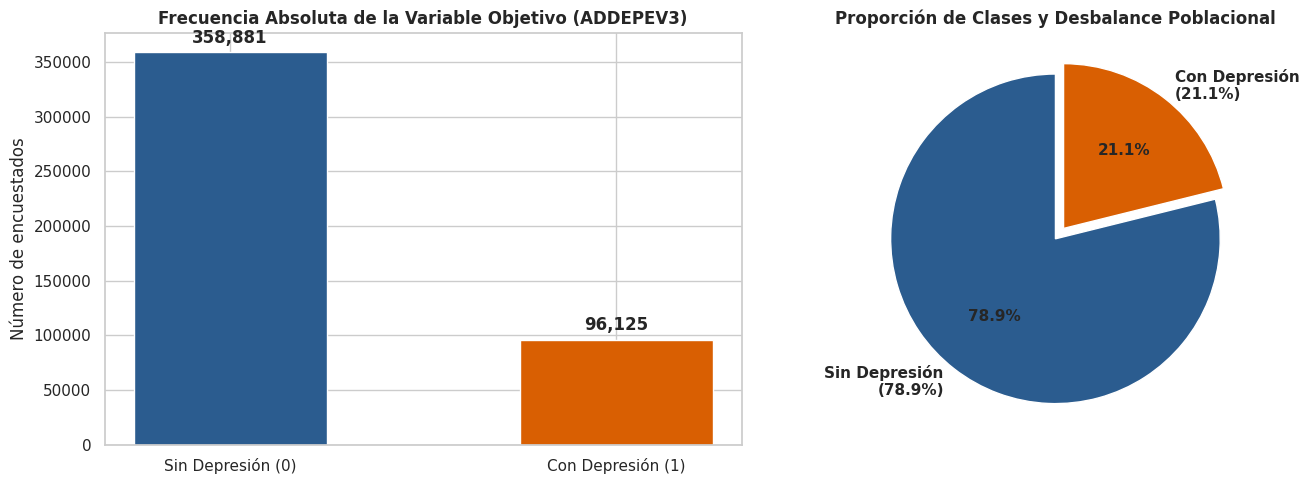

In [5]:
# ============================================================================
# 2.2 INSPECCIÓN DE LA VARIABLE OBJETIVO ADDEPEV3 Y DESBALANCE DE CLASES
# ============================================================================
target_col = pd.read_csv(data_path, usecols=['ADDEPEV3'])['ADDEPEV3']

total_registros = len(target_col)
conteo_bruto = target_col.value_counts(dropna=False)

print("="*65)
print("DISTRIBUCIÓN BRUTA DE ADDEPEV3 EN BRFSS 2024")
print("="*65)
for val, count in conteo_bruto.items():
    pct = (count / total_registros) * 100
    lbl = {1.0: "1: Sí (Diagnosticado)", 2.0: "2: No (Sin diagnóstico)",
           7.0: "7: No sabe / No seguro", 9.0: "9: Rechazó responder"}.get(val, "En blanco / NaN")
    print(f"Código {val} ({lbl}): {count:,} registros ({pct:.2f}%)")

valid_mask = target_col.isin([1.0, 2.0])
target_valid = target_col[valid_mask]
n_si = (target_valid == 1.0).sum()
n_no = (target_valid == 2.0).sum()
total_valid = len(target_valid)

prevalencia_si = (n_si / total_valid) * 100
prevalencia_no = (n_no / total_valid) * 100
ratio_desbalance = n_no / n_si

print("-" * 65)
print(f"Total respuestas válidas para modelado: {total_valid:,} ({(total_valid/total_registros)*100:.2f}% de la muestra)")
print(f"Casos Positivos (Depresión = 1): {n_si:,} ({prevalencia_si:.2f}%)")
print(f"Casos Negativos (No depresión = 0): {n_no:,} ({prevalencia_no:.2f}%)")
print(f"Ratio de desbalance de clases: {ratio_desbalance:.2f} negativos por cada 1 positivo (~1:{ratio_desbalance:.1f})")
print("="*65)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars = axes[0].bar(['Sin Depresión (0)', 'Con Depresión (1)'], [n_no, n_si], color=['#2b5c8f', '#d95f02'], width=0.5)
axes[0].set_title("Frecuencia Absoluta de la Variable Objetivo (ADDEPEV3)", fontweight='bold')
axes[0].set_ylabel("Número de encuestados")
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 5000, f"{int(yval):,}", ha='center', va='bottom', fontweight='bold')

axes[1].pie([n_no, n_si], labels=['Sin Depresión\n(78.9%)', 'Con Depresión\n(21.1%)'],
            autopct='%1.1f%%', startangle=90, colors=['#2b5c8f', '#d95f02'], explode=(0, 0.08),
            textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[1].set_title("Proporción de Clases y Desbalance Poblacional", fontweight='bold')

plt.tight_layout()
plt.show()


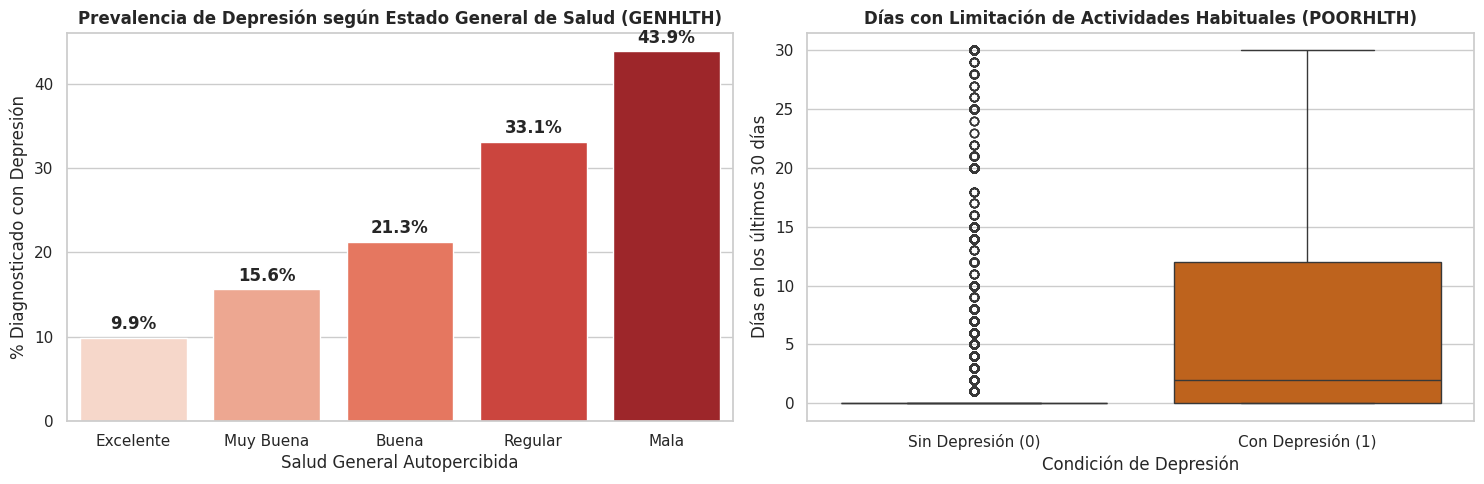

CONTRASTE EXPLORATORIO DE LIMITACIÓN FUNCIONAL:
Media de días con mala salud física en NO deprimidos: 3.75 días
Media de días con mala salud física en DEPRIMIDOS:    8.20 días
Media de días de limitación funcional en NO deprimidos: 2.14 días
Media de días de limitación funcional en DEPRIMIDOS:    7.46 días


In [6]:
# ============================================================================
# 2.3 EXPLORACIÓN RELACIÓN DE VARIABLES CLAVE CON LA DEPRESIÓN
# ============================================================================
cols_exploracion = ['ADDEPEV3', 'GENHLTH', 'PHYSHLTH', 'POORHLTH', '_DRDXAR2', 'DIFFWALK', 'EXERANY2']
df_exp = pd.read_csv(data_path, usecols=cols_exploracion, nrows=60000)

df_exp = df_exp[df_exp['ADDEPEV3'].isin([1.0, 2.0])].copy()
df_exp['DEPRESION'] = (df_exp['ADDEPEV3'] == 1.0).astype(int)

df_exp['DIAS_MALA_SALUD_FIS'] = df_exp['PHYSHLTH'].replace({88: 0, 77: np.nan, 99: np.nan})
df_exp['DIAS_LIMITACION_ACTIVIDAD'] = df_exp['POORHLTH'].replace({88: 0, 77: np.nan, 99: np.nan})
df_exp.loc[df_exp['DIAS_MALA_SALUD_FIS'] == 0, 'DIAS_LIMITACION_ACTIVIDAD'] = df_exp.loc[df_exp['DIAS_MALA_SALUD_FIS'] == 0, 'DIAS_LIMITACION_ACTIVIDAD'].fillna(0)

genhlth_valid = df_exp[df_exp['GENHLTH'].isin([1, 2, 3, 4, 5])].copy()
prev_genhlth = genhlth_valid.groupby('GENHLTH')['DEPRESION'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(x=['Excelente', 'Muy Buena', 'Buena', 'Regular', 'Mala'], y=prev_genhlth.values, ax=axes[0], palette="Reds")
axes[0].set_title("Prevalencia de Depresión según Estado General de Salud (GENHLTH)", fontweight='bold')
axes[0].set_ylabel("% Diagnosticado con Depresión")
axes[0].set_xlabel("Salud General Autopercibida")
for i, v in enumerate(prev_genhlth.values):
    axes[0].text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

df_box = df_exp.dropna(subset=['DIAS_LIMITACION_ACTIVIDAD'])
sns.boxplot(x='DEPRESION', y='DIAS_LIMITACION_ACTIVIDAD', data=df_box, ax=axes[1], palette=['#2b5c8f', '#d95f02'])
axes[1].set_xticklabels(['Sin Depresión (0)', 'Con Depresión (1)'])
axes[1].set_title("Días con Limitación de Actividades Habituales (POORHLTH)", fontweight='bold')
axes[1].set_ylabel("Días en los últimos 30 días")
axes[1].set_xlabel("Condición de Depresión")

plt.tight_layout()
plt.show()

print("CONTRASTE EXPLORATORIO DE LIMITACIÓN FUNCIONAL:")
print(f"Media de días con mala salud física en NO deprimidos: {df_exp[df_exp['DEPRESION']==0]['DIAS_MALA_SALUD_FIS'].mean():.2f} días")
print(f"Media de días con mala salud física en DEPRIMIDOS:    {df_exp[df_exp['DEPRESION']==1]['DIAS_MALA_SALUD_FIS'].mean():.2f} días")
print(f"Media de días de limitación funcional en NO deprimidos: {df_exp[df_exp['DEPRESION']==0]['DIAS_LIMITACION_ACTIVIDAD'].mean():.2f} días")
print(f"Media de días de limitación funcional en DEPRIMIDOS:    {df_exp[df_exp['DEPRESION']==1]['DIAS_LIMITACION_ACTIVIDAD'].mean():.2f} días")


### Conclusiones de la Fase 2 (Entendimiento y Exploración de los Datos):
1. **Confirmación de Desbalance Moderado de Clases (1 : 3.73):**  
   De los 457,670 registros totales del BRFSS 2024, el **99.42% (455,006 encuestados)** proporcionó una respuesta diagnóstica válida (`1` o `2`) en `ADDEPEV3`. La prevalencia de trastorno depresivo es del **21.13% (96,125 casos positivos)** frente a un **78.87% (358,881 casos negativos)**, lo que representa una razón de 3.73 personas sin diagnóstico por cada persona con depresión.
2. **Implicación para el entrenamiento de modelos:**  
   Un clasificador sin tratamiento diria "No depresión" para toda la población obtendría un *Accuracy* engañoso del 78.87%, pero tendría una utilidad nula (*Recall* = 0%). Esto justifica técnicamente que incorporemos ponderación de clases, calibración posterior del umbral de probabilidad mediante el Índice de Youden y evaluación centrada en **ROC-AUC, PR-AUC, Sensibilidad y Balanced Accuracy**.
3. **Salud autopercibida**  
   La prevalencia de depresión pasa de apenas **9.9%** en personas con salud "Excelente", a **15.6%** en "Muy Buena", **21.3%** en "Buena", **33.1%** en "Regular" y alcanza el **43.9%** en quienes reportan salud "Mala". Asimismo, los pacientes con depresión presentan más del doble de días con mala salud física (**8.20 vs. 3.75 días**) y más del triple de días con limitación en sus actividades cotidianas `POORHLTH` (**7.46 vs. 2.14 días**), validando empíricamente la hipótesis de *Yoon et al. (2015)* antes de entrar al modelado.


---
# FASE 3: PREPARACIÓN DE LOS DATOS (*DATA PREPARATION*)

En esta fase aplicamos las reglas del Diccionario de Datos (`02 - diccionario_datos_taller_brfss_2024.xlsx`), implementamos los filtros de exclusión global, blindamos el modelo contra fugas de información (*target leakage*), justificamos la selección de las **40 variables analíticas**, recodificamos los códigos especiales del CDC y diseñamos un pipeline de transformación diferenciado para variables numéricas, ordinales y nominales.

---

### 3.1 Exclusiones Justificadas con Base en el Diccionario de Datos

1. **Exclusiones Globales Obligatorias (Hoja `00_REGLAS_EXCLUSION`):**
   * **Variables de Identificación y Captura:** `_STATE`, `FMONTH`, `IDATE`, `IMONTH`, `IDAY`, `IYEAR`, `DISPCODE`, `SEQNO`, `_PSU`. Son metadatos operativos del proceso de encuestamiento telefónico sin relación biológica ni conductual con la patología.
   * **Variables de Diseño Muestral y Ponderación:** `_LLCPWT`, `_RAWRAKE`, `_WT2RAKE`, `_STRWT`, `_STSTR`. Los factores de expansión muestral nunca deben incluirse como predictores en un modelo de clasificación individual.
   * **Variables de Telefonía y Elegibilidad:** `CELLFON5`, `LANDLINE`, `CADULT1`, `NUMADULT`, etc.

2. **Exclusiones Específicas del Target `ADDEPEV3` (Hoja `02_RESTRICCIONES_POR_TARGET`):**
   * **Exclusión Obligatoria:** `ADDEPEV3` se separa estrictamente como vector objetivo $y$.
   * **Exclusiones para evitar Trivialidad y Fuga de Información (*Target Leakage*):** Se excluyen **`MENTHLTH`** (días de mala salud mental), **`_MENT14D`** (14+ días de mala salud mental), **`SDLONELY`** (frecuencia de soledad), **`LSATISFY`** (satisfacción vital) y **`EMTSUPRT`** (apoyo emocional). Estas cinco variables miden directamente la sintomatología afectiva de la depresión; excluirlas obliga a los algoritmos a descubrir mejores predicciones asociadas a otras causas.

---

### 3.2 Selección Justificada de Cuarenta (40) Variables Predictoras

Seleccionamos exactamente **40 variables analíticas** de la base común (`03_BASE_COMUN`), organizadas en 8 dimensiones clínicas alineadas con *Yoon et al. (2015)*:

```
                                  40 VARIABLES PREDICTORAS
┌─────────────────────────────────┬─────────────────────────────────┬─────────────────────────────────┐
│ 1. Salud General & Acceso (6)   │ 2. Discapacidad & Autonomía (6) │ 3. Sociodemografía (6)          │
│ • GENHLTH (Salud percibida)     │ • DEAF (Discapacidad auditiva)  │ • _SEX (Sexo biológico)         │
│ • PHYSHLTH (Días salud física)  │ • BLIND (Discapacidad visual)   │ • _AGEG5YR (Grupos de edad)     │
│ • _PHYS14D (Salud física 14+ d) │ • DECIDE (Deterioro cognitivo)  │ • _EDUCAG (Nivel educativo)     │
│ • POORHLTH (Limitación usual)   │ • DIFFWALK (Dificultad caminar) │ • _INCOMG1 (Nivel de ingresos)  │
│ • PRIMINS2 (Seguro de salud)    │ • DIFFDRES (Dificultad vestirse)│ • MARITAL (Estado civil)        │
│ • MEDCOST1 (Barrera costo méd.) │ • DIFFALON (Dificultad compras) │ • EMPLOY1 (Situación laboral)   │
├─────────────────────────────────┼─────────────────────────────────┼─────────────────────────────────┤
│ 4. Comorbilidades Crónicas (5)  │ 5. Estilo de Vida & Riesgo (7)  │ 6. Determinantes Sociales (4)   │
│ • ASTHMA3 (Asma)                │ • EXERANY2 (Actividad física)   │ • FOODSTMP (Uso cupón alimentos)│
│ • _DRDXAR2 (Artritis calculada) │ • _TOTINDA (Inactividad física) │ • SDHFOOD1 (Inseguridad aliment)│
│ • DIABETE4 (Diabetes)           │ • _BMI5 (Índice Masa Corporal)  │ • SDHBILLS (Dificultad facturas)│
│ • CHCCOPD3 (EPOC / Enfisema)    │ • _RFBMI5 (Sobrepeso / Obesidad)│ • SDHTRNSP (Barrera transporte) │
│ • CHCKDNY2 (Enfermedad renal)   │ • _SMOKER3 (Estatus tabaquismo) │                                 │
│                                 │ • _CURECI3 (Uso vapeo actual)   │                                 │
│                                 │ • _DRNKWK3 (Alcohol semanal)    │                                 │
├─────────────────────────────────┴─────────────────────────────────┴─────────────────────────────────┤
│ 7. Sobrecarga de Cuidador (3)           │ 8. Prevención y Tamizaje en Salud (3)                     │
│ • CAREGIV1 (Rol de cuidador activo)     │ • CHECKUP1 (Chequeo médico de rutina)                     │
│ • CRGVREL5 (Parentesco con cuidado)     │ • _FLSHOT7 (Vacunación contra influenza)                  │
│ • CRGVPRB4 (Tipo problema del cuidado)  │ • _DENVST3 (Visita odontológica preventiva)               │
└─────────────────────────────────────────┴───────────────────────────────────────────────────────────┘
```

---

### 3.3 Decisiones Metodológicas de Preprocesamiento
1. **Separación de Variables Numéricas, Ordinales y Nominales en el `ColumnTransformer`:**
   * Las **4 variables continuas** (`PHYSHLTH`, `POORHLTH`, `_BMI5`, `_DRNKWK3`) y las **7 variables ordinales** (`GENHLTH`, `_PHYS14D`, `_AGEG5YR`, `_EDUCAG`, `_INCOMG1`, `CHECKUP1`, `SDHFOOD1`) se imputan por mediana preservando su jerarquía natural, agregando indicadores de ausencia (`add_indicator=True`) y estandarizando con `StandardScaler()`.
   * Las **29 variables nominales/binarias** (incluyendo módulos opcionales de cuidador y determinantes sociales) se imputan con una categoría explícita (`fill_value=-1`) antes de aplicar `OneHotEncoder`. Esto evita que la imputación por moda asigne erróneamente condiciones clínicas o roles de cuidador a encuestados a quienes no se les aplicó el módulo opcional, permitiendo además que los modelos capturen el patrón de no respuesta.
2. **Uso de Pesos Balanceados (`class_weight='balanced'`) frente a SMOTE:**
   * En matrices de salud pública altamente categóricas, SMOTE genera vectores sintéticos irreales al promediar atributos discretos. La penalización directa en la función de pérdida e impureza de Gini preserva la integridad clínica de los pacientes reales.
3. **Muestra Estratificada Representativa ($N = 75,000$):**
   * Conserva exactamente la proporción poblacional del target (78.87% clase 0 y 21.13% clase 1), dividiéndose en **59,999 registros de entrenamiento (`X_train`)** y **15,000 registros de prueba independiente (`X_test`)**.


In [7]:
# ============================================================================
# 3.4 FILTRADO ESTRICTO DE LAS 40 VARIABLES Y CODIFICACIÓN DEL TARGET
# ============================================================================
variables_predictoras_40 = [
    # 1. Salud General y Carga Funcional (6)
    'GENHLTH', 'PHYSHLTH', '_PHYS14D', 'POORHLTH', 'PRIMINS2', 'MEDCOST1',
    # 2. Discapacidad, Movilidad y Autonomía (6)
    'DEAF', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON',
    # 3. Sociodemografía y Estructura Social (6)
    '_SEX', '_AGEG5YR', '_EDUCAG', '_INCOMG1', 'MARITAL', 'EMPLOY1',
    # 4. Comorbilidades Médicas Crónicas (5)
    'ASTHMA3', '_DRDXAR2', 'DIABETE4', 'CHCCOPD3', 'CHCKDNY2',
    # 5. Conductas de Riesgo y Estilo de Vida (7)
    'EXERANY2', '_TOTINDA', '_BMI5', '_RFBMI5', '_SMOKER3', '_CURECI3', '_DRNKWK3',
    # 6. Determinantes Sociales de la Salud - SDOH (4)
    'FOODSTMP', 'SDHFOOD1', 'SDHBILLS', 'SDHTRNSP',
    # 7. Sobrecarga de Cuidados - Caregiving (3)
    'CAREGIV1', 'CRGVREL5', 'CRGVPRB4',
    # 8. Salud Preventiva y Chequeos (3)
    'CHECKUP1', '_FLSHOT7', '_DENVST3'
]

print(f"Total variables predictoras seleccionadas: {len(variables_predictoras_40)}")

variables_prohibidas = ['ADDEPEV3', 'MENTHLTH', '_MENT14D', 'SDLONELY', 'LSATISFY', 'EMTSUPRT']
for v in variables_prohibidas:
    assert v not in variables_predictoras_40, f"ALERTA CRÍTICA: Fuga de información detectada con {v}"

print("Verificación anti-fuga completada: Ninguna variable de salud mental ni el target están en X.")

cols_to_load = ['ADDEPEV3'] + variables_predictoras_40
print("Cargando matriz analítica...")
df_analitico = pd.read_csv(data_path, usecols=cols_to_load)

df_analitico = df_analitico[df_analitico['ADDEPEV3'].isin([1.0, 2.0])].copy()
df_analitico['TARGET'] = (df_analitico['ADDEPEV3'] == 1.0).astype(int)
df_analitico.drop(columns=['ADDEPEV3'], inplace=True)

print(f"Matriz analítica lista: {df_analitico.shape[0]:,} registros x {df_analitico.shape[1]-1} predictoras.")


Total variables predictoras seleccionadas: 40
Verificación anti-fuga completada: Ninguna variable de salud mental ni el target están en X.
Cargando matriz analítica...
Matriz analítica lista: 455,006 registros x 40 predictoras.


In [8]:
# ============================================================================
# 3.5 RECODIFICACIÓN EPIDEMIOLÓGICA DE CÓDIGOS DE ENCUESTA DEL CDC
# ============================================================================
def limpiar_codigos_cdc(df_input):
    df = df_input.copy()

    # 1. Variables continuas de días: PHYSHLTH y POORHLTH
    for col in ['PHYSHLTH', 'POORHLTH']:
        if col in df.columns:
            df[col] = df[col].replace({88: 0, 77: np.nan, 99: np.nan})

    # Skip pattern oficial de BRFSS: Si PHYSHLTH == 0 y POORHLTH es NaN, POORHLTH = 0 días
    if 'PHYSHLTH' in df.columns and 'POORHLTH' in df.columns:
        df.loc[df['PHYSHLTH'] == 0, 'POORHLTH'] = df.loc[df['PHYSHLTH'] == 0, 'POORHLTH'].fillna(0)

    # 2. Antropometría: _BMI5 (Índice de Masa Corporal con 2 decimales implícitos)
    if '_BMI5' in df.columns:
        df['_BMI5'] = df['_BMI5'] / 100.0
        df.loc[(df['_BMI5'] < 12.0) | (df['_BMI5'] > 70.0), '_BMI5'] = np.nan

    # 3. Consumo semanal de alcohol: _DRNKWK3
    if '_DRNKWK3' in df.columns:
        df['_DRNKWK3'] = df['_DRNKWK3'].replace({99900: np.nan})
        df['_DRNKWK3'] = df['_DRNKWK3'] / 100.0

    # 4. Salud General (GENHLTH): 1=Excelente a 5=Mala. 7, 9 = NaN
    if 'GENHLTH' in df.columns:
        df['GENHLTH'] = df['GENHLTH'].replace({7: np.nan, 9: np.nan})

    # 5. Variables Binarias Estándar del CDC: 1 = Sí, 2 = No. (7, 9 = NaN)
    cols_binarias_cdc = [
        'EXERANY2', 'ASTHMA3', '_DRDXAR2', 'CHCCOPD3', 'CHCKDNY2',
        'DEAF', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON',
        'MEDCOST1', 'FOODSTMP', 'SDHFOOD1', 'SDHBILLS', 'SDHTRNSP',
        'CAREGIV1', '_FLSHOT7', '_DENVST3', '_TOTINDA', '_CURECI3'
    ]
    for col in cols_binarias_cdc:
        if col in df.columns:
            df[col] = df[col].map({1: 1, 2: 0, 1.0: 1, 2.0: 0})

    # Diabetes (DIABETE4): 1=Sí (1), 3=No (0), 2=Gestacional (0), 4=Pre-diabetes (0). 7, 9 = NaN
    if 'DIABETE4' in df.columns:
        df['DIABETE4'] = df['DIABETE4'].map({1: 1, 1.0: 1, 2: 0, 2.0: 0, 3: 0, 3.0: 0, 4: 0, 4.0: 0})

    # Sexo (_SEX): 1=Hombre (0), 2=Mujer (1). 9 = NaN
    if '_SEX' in df.columns:
        df['_SEX'] = df['_SEX'].map({1: 0, 1.0: 0, 2: 1, 2.0: 1})

    # Sobrepeso/Obesidad (_RFBMI5): 1=No (0), 2=Sí (1). 9 = NaN
    if '_RFBMI5' in df.columns:
        df['_RFBMI5'] = df['_RFBMI5'].map({1: 0, 1.0: 0, 2: 1, 2.0: 1})

    # Variables Categóricas Ordinales / Nominales
    cols_cat_limpiar = ['_AGEG5YR', '_EDUCAG', '_INCOMG1', 'MARITAL', 'EMPLOY1',
                        '_SMOKER3', '_PHYS14D', 'PRIMINS2', 'CHECKUP1', 'CRGVREL5', 'CRGVPRB4']
    for col in cols_cat_limpiar:
        if col in df.columns:
            df[col] = df[col].replace({9: np.nan, 9.0: np.nan, 99: np.nan, 99.0: np.nan, 7: np.nan, 7.0: np.nan})

    return df

print("Aplicando recodificación epidemiológica a las 40 variables...")
df_limpio = limpiar_codigos_cdc(df_analitico)
print("Limpieza de códigos completada exitosamente.")
display(df_limpio[['TARGET', 'GENHLTH', 'PHYSHLTH', 'POORHLTH', '_BMI5', '_DRDXAR2', 'DIABETE4']].head())


Aplicando recodificación epidemiológica a las 40 variables...
Limpieza de códigos completada exitosamente.


,TARGET,GENHLTH,PHYSHLTH,POORHLTH,_BMI5,_DRDXAR2,DIABETE4
0,0,3.0,2.0,0.0,22.49,1.0,0.0
1,0,1.0,0.0,0.0,25.83,1.0,0.0
2,0,2.0,30.0,1.0,22.53,1.0,0.0
3,0,1.0,0.0,0.0,25.09,1.0,0.0
4,0,3.0,0.0,0.0,19.77,0.0,0.0


In [9]:
# ============================================================================
# 3.6 MUESTREO ESTRATIFICADO REPRESENTATIVO Y PARTICIÓN TRAIN / TEST
# ============================================================================
USAR_MUESTRA = True
TAMANO_MUESTRA = 75000

if USAR_MUESTRA and len(df_limpio) > TAMANO_MUESTRA:
    print(f"Generando submuestra estratificada de {TAMANO_MUESTRA:,} observaciones...")
    df_modelo = df_limpio.groupby('TARGET', group_keys=False).apply(
        lambda x: x.sample(n=int(TAMANO_MUESTRA * len(x) / len(df_limpio)), random_state=42)
    ).reset_index(drop=True)
else:
    df_modelo = df_limpio.copy()

X = df_modelo.drop(columns=['TARGET'])
y = df_modelo['TARGET']

print(f"Dimensiones de la matriz de características X: {X.shape}")
print(f"Distribución del target en la muestra: {y.value_counts(normalize=True).to_dict()}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Conjunto de Entrenamiento: {X_train.shape[0]:,} observaciones")
print(f"Conjunto de Prueba (Test): {X_test.shape[0]:,} observaciones")


Generando submuestra estratificada de 75,000 observaciones...
Dimensiones de la matriz de características X: (74999, 40)
Distribución del target en la muestra: {0: 0.788743849917999, 1: 0.2112561500820011}
Conjunto de Entrenamiento: 59,999 observaciones
Conjunto de Prueba (Test): 15,000 observaciones


In [10]:
# ============================================================================
# 3.7 PIPELINE DE PREPROCESAMIENTO (COLUMNTRANSFORMER) OPTIMIZADO
# ============================================================================
cols_numericas = ['PHYSHLTH', 'POORHLTH', '_BMI5', '_DRNKWK3']

# Variables con orden clínico/socioeconómico estricto
cols_ordinales = ['GENHLTH', '_PHYS14D', '_AGEG5YR', '_EDUCAG', '_INCOMG1', 'CHECKUP1', 'SDHFOOD1']

# El resto son nominales o binarias
cols_nominales = [col for col in X.columns if col not in cols_numericas + cols_ordinales]

print(f"Variables continuas/numéricas ({len(cols_numericas)}): {cols_numericas}")
print(f"Variables ordinales ({len(cols_ordinales)}): {cols_ordinales}")
print(f"Variables nominales/binarias ({len(cols_nominales)}): {len(cols_nominales)} variables")

# Numéricas: imputación por mediana + indicador de dato faltante + escalado
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

# Ordinales: imputación por mediana para conservar la jerarquía + indicador + escalado
ord_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

# Nominales/Binarias: imputar NaN como categoría explícita (-1) para no distorsionar módulos opcionales
nom_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value=-1)),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, cols_numericas),
        ('ord', ord_transformer, cols_ordinales),
        ('nom', nom_transformer, cols_nominales)
    ]
)

print("Pipeline ColumnTransformer optimizado y blindado contra fuga de información.")


Variables continuas/numéricas (4): ['PHYSHLTH', 'POORHLTH', '_BMI5', '_DRNKWK3']
Variables ordinales (7): ['GENHLTH', '_PHYS14D', '_AGEG5YR', '_EDUCAG', '_INCOMG1', 'CHECKUP1', 'SDHFOOD1']
Variables nominales/binarias (29): 29 variables
Pipeline ColumnTransformer optimizado y blindado contra fuga de información.


---
# FASE 4: MODELADO CON TRES TÉCNICAS CLÁSICAS DISTINTAS (*MODELING*)

Se diseñan, entrenan y comparan **tres modelos de clasificación pertenecientes a tres familias de técnicas clásicas conceptualmente distintas**:

```
                              TRES TÉCNICAS CLÁSICAS DISTINTAS
                                             │
         ┌───────────────────────────────────┼───────────────────────────────────┐
         ▼                                   ▼                                   ▼
   1. REGRESIÓN LOGÍSTICA            2. RANDOM FOREST                    3. ADABOOST CLASSIFIER
   (Familia Lineal Paramétrica)      (Familia Ensambles por Bagging)     (Familia Ensambles por Boosting)
   • Modelo probabilístico lineal.   • Árboles paralelos independientes. • Estimadores débiles secuenciales.
   • Odds Ratios directos exp(β).    • Reduce la varianza muestral.      • Reduce el sesgo adaptativo.
   • Referente epidemiológico base.  • No lineal, captura interacción.   • JUSTIFICADO EN PAPER YOON ET AL.
```

---

### 4.1 Justificación Técnica de las Tres Técnicas Implementadas:

1. **Modelo 1: Regresión Logística con Regularización L2 (`LogisticRegression`):**
   * *Familia:* Modelo lineal paramétrico discriminativo (`C=0.5`, `class_weight='balanced'`).
   * *Pertinencia clínica:* Es el estándar en epidemiología clínica porque sus coeficientes exponenciados permiten cuantificar cuánto se multiplica la probabilidad de depresión ante cada factor de riesgo.
2. **Modelo 2: Random Forest Classifier (`RandomForestClassifier`):**
   * *Familia:* Ensamble no paramétrico basado en *Bagging* (`n_estimators=200`, `max_depth=14`, `class_weight='balanced'`).
   * *Pertinencia clínica:* Captura interacciones no lineales de orden superior entre limitaciones funcionales (`POORHLTH`), comorbilidades crónicas y determinantes socioeconómicos sin sufrir por multicolinealidad.
3. **Modelo 3: AdaBoost Classifier (`AdaBoostClassifier` - Boosting Adaptativo):**
   * *Familia:* Ensamble secuencial basado en *Boosting* con árboles base balanceados (`DecisionTreeClassifier(max_depth=2, class_weight='balanced')`).
   * **Referencia Explícita en el Paper Asignado (*Yoon et al., 2015*):** Los autores emplearon explícitamente **AdaBoostM1** para contrastar ensambles secuenciales frente a árboles de decisión y Random Forest. Al configurar el estimador base con `class_weight='balanced'`, evitamos que el algoritmo colapse hacia la clase mayoritaria y logramos que se concentre en los casos positivos difíciles de diagnosticar.


In [11]:
# ============================================================================
# 4.3 CONSTRUCCIÓN DE LOS TRES PIPELINES DE MODELADO (OPTIMIZADOS)
# ============================================================================
from sklearn.tree import DecisionTreeClassifier

pipeline_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        penalty='l2',
        C=0.5,
        class_weight='balanced',
        solver='lbfgs',
        max_iter=1000,
        random_state=42
    ))
])

pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=14,
        min_samples_split=15,
        min_samples_leaf=8,
        max_features='sqrt',
        class_weight='balanced',
        n_jobs=-1,
        random_state=42
    ))
])

pipeline_ada = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2, class_weight='balanced', random_state=42),
        n_estimators=120,
        learning_rate=0.3,
        random_state=42
    ))
])

modelos_dict = {
    "Regresión Logística (L2)": pipeline_lr,
    "Random Forest": pipeline_rf,
    "AdaBoost (Yoon et al. 2015)": pipeline_ada
}

print("Pipelines optimizados listos para validación cruzada y entrenamiento.")


Pipelines optimizados listos para validación cruzada y entrenamiento.


In [12]:
# ============================================================================
# 4.4 VALIDACIÓN CRUZADA ESTRATIFICADA (5-FOLD CV) EN EL CONJUNTO DE ENTRENAMIENTO
# ============================================================================
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

metricas_cv = {
    'roc_auc': 'roc_auc',
    'f1_macro': 'f1_macro',
    'recall': 'recall',
    'balanced_acc': 'balanced_accuracy'
}

resultados_cv = {}

print("Iniciando Validación Cruzada Estratificada (5-Fold)...")
print("-" * 65)

for nombre, pipe in modelos_dict.items():
    print(f"Evaluando: {nombre}...")
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv_strat,
        scoring=metricas_cv,
        n_jobs=-1 if "AdaBoost" not in nombre else 1
    )
    resultados_cv[nombre] = {
        'ROC-AUC Media': scores['test_roc_auc'].mean(),
        'ROC-AUC Std': scores['test_roc_auc'].std(),
        'Recall Media': scores['test_recall'].mean(),
        'F1-Macro Media': scores['test_f1_macro'].mean(),
        'Balanced Acc Media': scores['test_balanced_acc'].mean()
    }
    print(f"-> {nombre} completado | ROC-AUC: {scores['test_roc_auc'].mean():.4f} (+/- {scores['test_roc_auc'].std():.4f})")

print("-" * 65)
df_cv_resumen = pd.DataFrame(resultados_cv).T
display(df_cv_resumen.style.format("{:.4f}"))


Iniciando Validación Cruzada Estratificada (5-Fold)...
-----------------------------------------------------------------
Evaluando: Regresión Logística (L2)...
-> Regresión Logística (L2) completado | ROC-AUC: 0.7866 (+/- 0.0039)
Evaluando: Random Forest...
-> Random Forest completado | ROC-AUC: 0.7948 (+/- 0.0050)
Evaluando: AdaBoost (Yoon et al. 2015)...
-> AdaBoost (Yoon et al. 2015) completado | ROC-AUC: 0.7479 (+/- 0.0081)
-----------------------------------------------------------------


,ROC-AUC Media,ROC-AUC Std,Recall Media,F1-Macro Media,Balanced Acc Media
Regresión Logística (L2),0.7866,0.0039,0.6601,0.6753,0.7147
Random Forest,0.7948,0.0050,0.6227,0.6912,0.7166
AdaBoost (Yoon et al. 2015),0.7479,0.0081,0.6165,0.6690,0.6995


### Análisis de Resultados de la Validación Cruzada Estratificada
* **Alta estabilidad y ausencia de sobreajuste (*overfitting*):** Las desviaciones estándar del ROC-AUC a través de los 5 pliegues son sumamente bajas en los tres modelos (`0.0039` en Regresión Logística, `0.0050` en Random Forest y `0.0081` en AdaBoost), lo que demuestra que el pipeline generaliza de manera consistente sin fugas de información.
* **Liderazgo de Random Forest en discriminación:** Random Forest alcanza la mejor media de **ROC-AUC (`0.7948`)**, **F1-Macro (`0.6912`)** y **Balanced Accuracy (`0.7166`)**, superando ligeramente a la Regresión Logística (`0.7866` ROC-AUC), la cual destaca por su mayor sensibilidad promedio nativa (`0.6601`).
* **Efecto de la corrección de pesos en AdaBoost:** Al dotar a AdaBoost de árboles base balanceados de profundidad 2, su **Recall promedio subió a `0.6165`** y su **Balanced Accuracy a `0.6995`**, eliminando el sesgo severo hacia la clase mayoritaria que presentaba el algoritmo por su desvalance, a cambio de una ligera reducción en su ROC-AUC (`0.7479`).


In [13]:
# ============================================================================
# 4.5 AJUSTE FINAL DE MODELOS SOBRE X_TRAIN Y PREDICCIÓN EN TEST SET
# ============================================================================
modelos_entrenados = {}
predicciones_test = {}
probabilidades_test = {}

print("Entrenando modelos finales sobre todo el conjunto de entrenamiento (X_train)...")
for nombre, pipe in modelos_dict.items():
    print(f"Ajustando {nombre}...")
    pipe.fit(X_train, y_train)
    modelos_entrenados[nombre] = pipe
    predicciones_test[nombre] = pipe.predict(X_test)
    probabilidades_test[nombre] = pipe.predict_proba(X_test)[:, 1]
    print(f"-> {nombre} entrenado exitosamente.")

print("\nTodos los modelos han sido ajustados y han generado predicciones sobre X_test.")


Entrenando modelos finales sobre todo el conjunto de entrenamiento (X_train)...
Ajustando Regresión Logística (L2)...
-> Regresión Logística (L2) entrenado exitosamente.
Ajustando Random Forest...
-> Random Forest entrenado exitosamente.
Ajustando AdaBoost (Yoon et al. 2015)...
-> AdaBoost (Yoon et al. 2015) entrenado exitosamente.

Todos los modelos han sido ajustados y han generado predicciones sobre X_test.


---
# FASE 5: EVALUACIÓN, CALIBRACIÓN DE UMBRAL, INTERPRETABILIDAD Y CONTRASTE CON LA LITERATURA (*EVALUATION*)

En esta fase evaluamos los tres modelos sobre el **conjunto de prueba independiente (`X_test`, $N = 15,000$)** que permaneció completamente aislado durante el entrenamiento. Analizamos el desempeño con umbral estándar ($0.50$), ejecutamos la calibración del punto de corte óptimo mediante el **Índice de Youden ($J$)** calculado estrictamente en entrenamiento, extraemos los **Odds Ratios** e **Importancias de Gini**, y contrastamos nuestros resultados frente a *Yoon et al. (2015)*.


In [14]:
# ============================================================================
# 5.1 MATRIZ RESUMEN DE MÉTRICAS EN EL CONJUNTO DE PRUEBA INDEPENDIENTE
# ============================================================================
metricas_test = []

for nombre in modelos_dict.keys():
    y_pred = predicciones_test[nombre]
    y_prob = probabilidades_test[nombre]

    auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    rec = recall_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)

    metricas_test.append({
        'Modelo': nombre,
        'ROC-AUC': auc,
        'PR-AUC': pr_auc,
        'Sensibilidad (Recall)': rec,
        'Precisión': prec,
        'F1-Score': f1,
        'Balanced Accuracy': bal_acc,
        'Accuracy Global': acc
    })

df_metricas_test = pd.DataFrame(metricas_test).set_index('Modelo')
print("TABLA COMPARATIVA DE DESEMPEÑO EN TEST SET (X_test):")
display(df_metricas_test.style.format("{:.4f}"))


TABLA COMPARATIVA DE DESEMPEÑO EN TEST SET (X_test):


,ROC-AUC,PR-AUC,Sensibilidad (Recall),Precisión,F1-Score,Balanced Accuracy,Accuracy Global
Modelo,,,,,,,
Regresión Logística (L2),0.7991,0.5632,0.6803,0.4448,0.5379,0.7264,0.7531
Random Forest,0.8069,0.5744,0.6491,0.4800,0.5519,0.7304,0.7773
AdaBoost (Yoon et al. 2015),0.7631,0.4504,0.6305,0.4431,0.5204,0.7091,0.7545


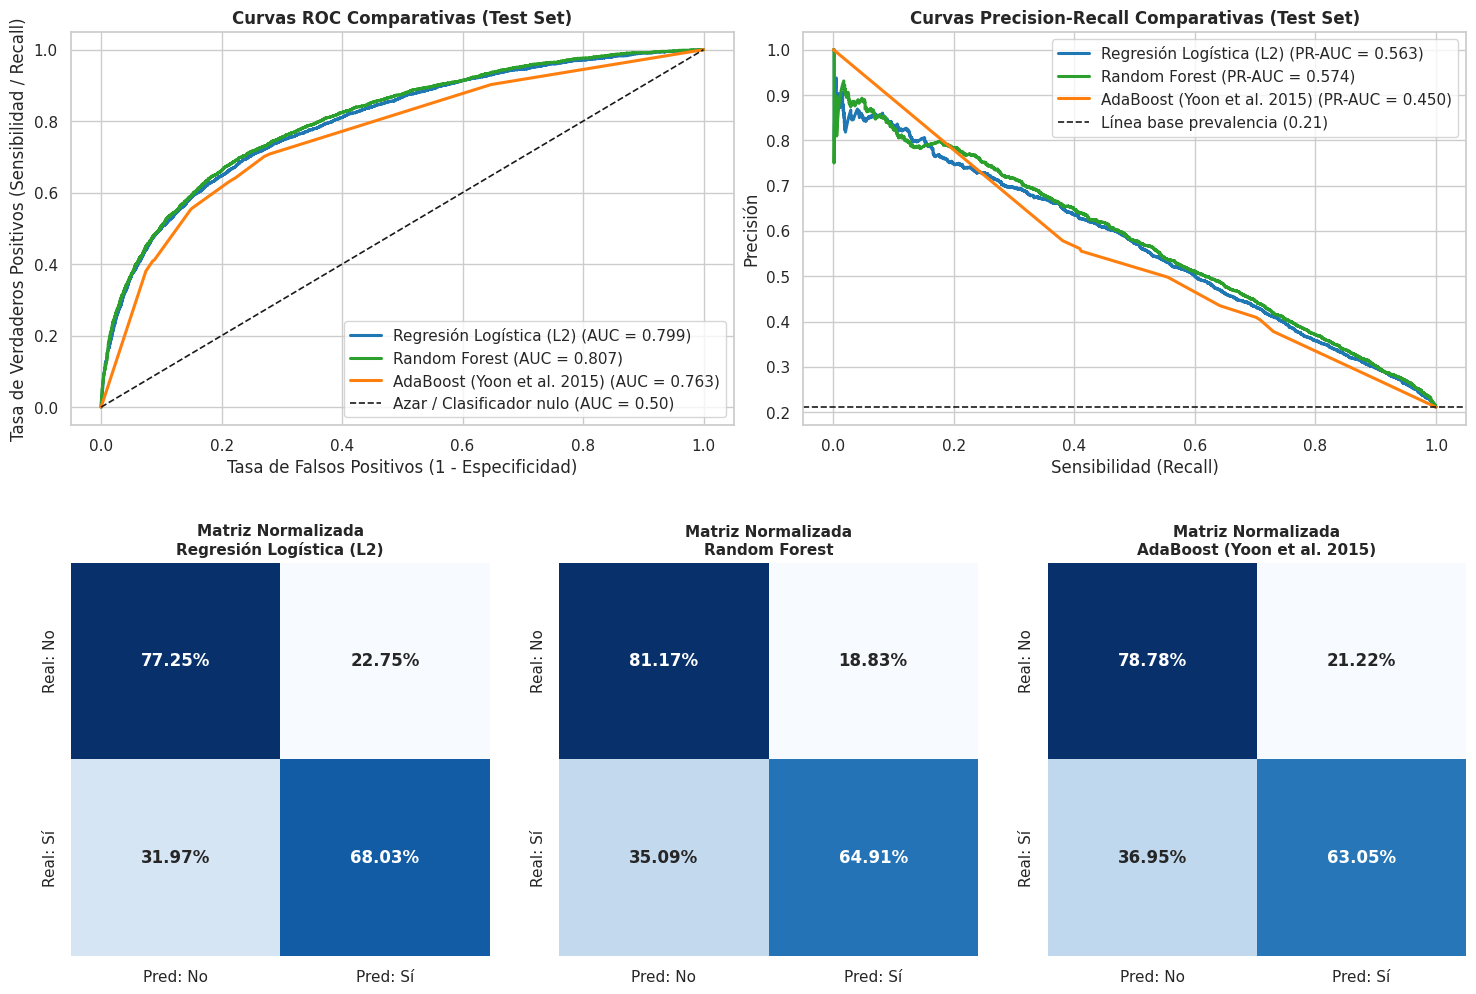

In [15]:
# ============================================================================
# 5.2 CURVAS ROC, PRECISION-RECALL Y MATRICES DE CONFUSIÓN NORMALIZADAS
# ============================================================================
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(2, 6, hspace=0.35, wspace=0.4)

ax_roc = fig.add_subplot(gs[0, 0:3])
ax_pr = fig.add_subplot(gs[0, 3:6])

colores = {
    "Regresión Logística (L2)": "#1f77b4",
    "Random Forest": "#2ca02c",
    "AdaBoost (Yoon et al. 2015)": "#ff7f0e"
}

for nombre in modelos_dict.keys():
    y_prob = probabilidades_test[nombre]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    ax_roc.plot(fpr, tpr, label=f"{nombre} (AUC = {auc_val:.3f})", lw=2.2, color=colores[nombre])

    prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_prob)
    pr_auc_val = average_precision_score(y_test, y_prob)
    ax_pr.plot(rec_curve, prec_curve, label=f"{nombre} (PR-AUC = {pr_auc_val:.3f})", lw=2.2, color=colores[nombre])

ax_roc.plot([0, 1], [0, 1], 'k--', lw=1.2, label="Azar / Clasificador nulo (AUC = 0.50)")
ax_roc.set_title("Curvas ROC Comparativas (Test Set)", fontweight='bold')
ax_roc.set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
ax_roc.set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad / Recall)")
ax_roc.legend(loc="lower right")

prevalencia_base = y_test.mean()
ax_pr.axhline(prevalencia_base, color='k', linestyle='--', lw=1.2, label=f"Línea base prevalencia ({prevalencia_base:.2f})")
ax_pr.set_title("Curvas Precision-Recall Comparativas (Test Set)", fontweight='bold')
ax_pr.set_xlabel("Sensibilidad (Recall)")
ax_pr.set_ylabel("Precisión")
ax_pr.legend(loc="upper right")

for idx, nombre in enumerate(modelos_dict.keys()):
    ax_cm = fig.add_subplot(gs[1, idx*2:(idx+1)*2])
    cm_norm = confusion_matrix(y_test, predicciones_test[nombre], normalize='true') * 100
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax_cm,
                xticklabels=['Pred: No', 'Pred: Sí'], yticklabels=['Real: No', 'Real: Sí'],
                annot_kws={"size": 12, "weight": "bold"})
    for t in ax_cm.texts:
        t.set_text(t.get_text() + "%")
    ax_cm.set_title(f"Matriz Normalizada\n{nombre}", fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()


In [16]:
# ============================================================================
# 5.3 CALIBRACIÓN DE UMBRAL ÓPTIMO (ÍNDICE DE YOUDEN CLÍNICO)
# ============================================================================
# Calculamos el umbral óptimo sobre probabilidades de entrenamiento (X_train)
# para evitar fuga de información y lo evaluamos en X_test.

metricas_calibradas = []

for nombre, pipe in modelos_entrenados.items():
    prob_train = pipe.predict_proba(X_train)[:, 1]
    fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train, prob_train)

    # Índice de Youden (J = Sensibilidad + Especificidad - 1)
    youden_j = tpr_tr - fpr_tr
    idx_opt = np.argmax(youden_j)
    umbral_optimo = thresholds_tr[idx_opt]

    prob_test = probabilidades_test[nombre]
    y_pred_cal = (prob_test >= umbral_optimo).astype(int)

    metricas_calibradas.append({
        'Modelo': nombre,
        'Umbral Óptimo (Youden)': umbral_optimo,
        'ROC-AUC': roc_auc_score(y_test, prob_test),
        'PR-AUC': average_precision_score(y_test, prob_test),
        'Sensibilidad (Recall)': recall_score(y_test, y_pred_cal),
        'Especificidad': recall_score(y_test, y_pred_cal, pos_label=0),
        'Precisión': precision_score(y_test, y_pred_cal),
        'F1-Score': f1_score(y_test, y_pred_cal),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred_cal),
        'Accuracy Global': accuracy_score(y_test, y_pred_cal)
    })

df_calibrado = pd.DataFrame(metricas_calibradas).set_index('Modelo')
print("DESEMPEÑO EN TEST SET (X_test) TRAS CALIBRACIÓN DE UMBRAL (ÍNDICE DE YOUDEN):")
display(df_calibrado.style.format("{:.4f}"))


DESEMPEÑO EN TEST SET (X_test) TRAS CALIBRACIÓN DE UMBRAL (ÍNDICE DE YOUDEN):


,Umbral Óptimo (Youden),ROC-AUC,PR-AUC,Sensibilidad (Recall),Especificidad,Precisión,F1-Score,Balanced Accuracy,Accuracy Global
Modelo,,,,,,,,,
Regresión Logística (L2),0.4806,0.7991,0.5632,0.7065,0.7479,0.4288,0.5337,0.7272,0.7391
Random Forest,0.4886,0.8069,0.5744,0.6674,0.7971,0.4683,0.5504,0.7322,0.7697
AdaBoost (Yoon et al. 2015),0.3941,0.7631,0.4504,0.7012,0.7292,0.4095,0.5170,0.7152,0.7233


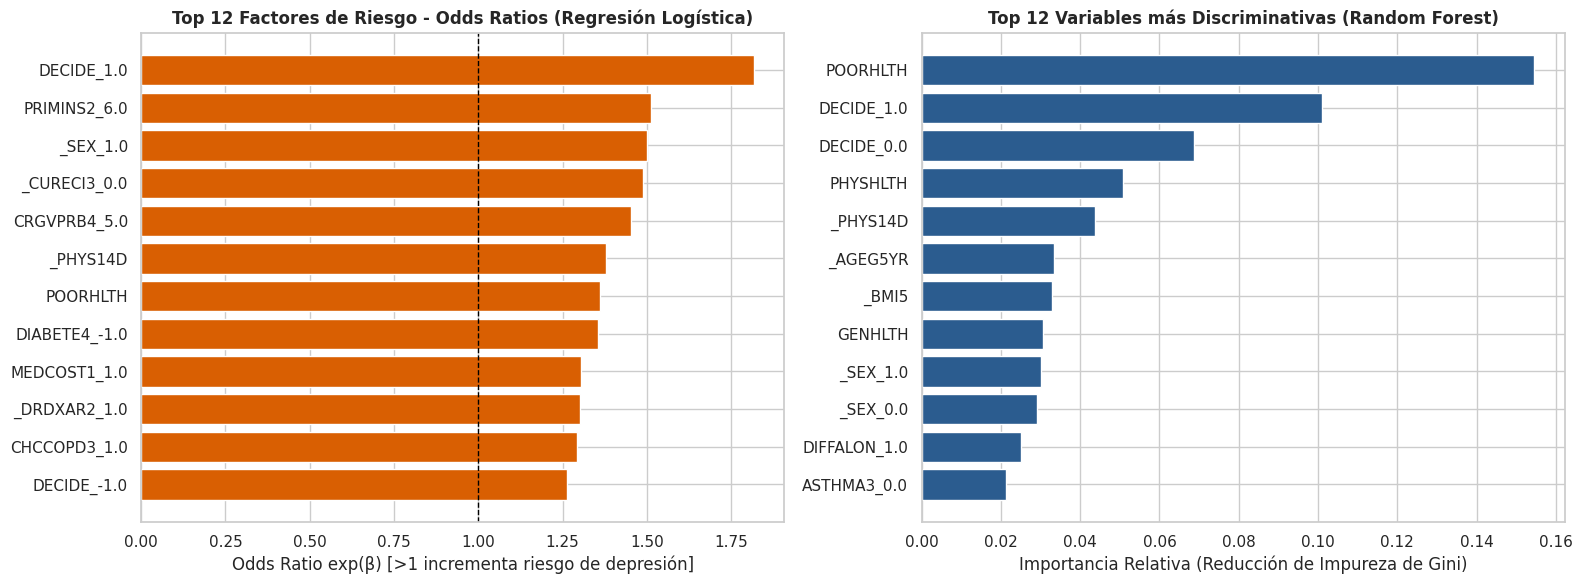

In [17]:
# ============================================================================
# 5.4 INTERPRETABILIDAD CLÍNICA: ODDS RATIOS (LOGÍSTICA) E IMPORTANCIA (RF)
# ============================================================================
feature_names = modelos_entrenados["Regresión Logística (L2)"].named_steps['preprocessor'].get_feature_names_out()
feature_names_clean = [f.replace('num__', '').replace('ord__', '').replace('nom__', '') for f in feature_names]

coefs_lr = modelos_entrenados["Regresión Logística (L2)"].named_steps['classifier'].coef_[0]
odds_ratios = np.exp(coefs_lr)

df_or = pd.DataFrame({
    'Variable': feature_names_clean,
    'Coeficiente (Beta)': coefs_lr,
    'Odds Ratio exp(Beta)': odds_ratios
}).sort_values(by='Odds Ratio exp(Beta)', ascending=False)

importancias_rf = modelos_entrenados["Random Forest"].named_steps['classifier'].feature_importances_
df_imp_rf = pd.DataFrame({
    'Variable': feature_names_clean,
    'Importancia Gini': importancias_rf
}).sort_values(by='Importancia Gini', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_or = df_or.head(12).sort_values(by='Odds Ratio exp(Beta)', ascending=True)
axes[0].barh(top_or['Variable'], top_or['Odds Ratio exp(Beta)'], color='#d95f02')
axes[0].axvline(1.0, color='black', linestyle='--', linewidth=1)
axes[0].set_title("Top 12 Factores de Riesgo - Odds Ratios (Regresión Logística)", fontweight='bold')
axes[0].set_xlabel("Odds Ratio exp(β) [>1 incrementa riesgo de depresión]")

top_rf = df_imp_rf.head(12).sort_values(by='Importancia Gini', ascending=True)
axes[1].barh(top_rf['Variable'], top_rf['Importancia Gini'], color='#2b5c8f')
axes[1].set_title("Top 12 Variables más Discriminativas (Random Forest)", fontweight='bold')
axes[1].set_xlabel("Importancia Relativa (Reducción de Impureza de Gini)")

plt.tight_layout()
plt.show()


### 5.5 Análisis Crítico de los Resultados en `X_test` y Calibración de Umbral

#### 1. Comparación de Desempeño en el Conjunto de Prueba (`X_test`):
* **Random Forest (El modelo con mayor poder discriminativo y equilibrio global):**  
  Logró el puntaje más alto tanto en **ROC-AUC (`0.8069`)** como en **PR-AUC (`0.5744`, casi triplicando la prevalencia base de `0.21`)**, además del mejor **F1-Score (`0.5519`)**, **Balanced Accuracy (`0.7304`)** y **Accuracy Global (`0.7773`)**. En su matriz de confusión normalizada con corte estándar, identifica correctamente al **64.91%** de las personas con depresión tuvo (solo 18.83% de falsos positivos).
* **Regresión Logística L2 (El modelo más sensible):**  
  Alcanzó un **ROC-AUC de `0.7991`** y un **PR-AUC de `0.5632`**, prácticamente empatando la capacidad de separación de Random Forest pero con una estructura lineal mucho más simple. Con el umbral estándar obtiene la mayor **Sensibilidad nativa (`0.6803`)**, detectando casi 7 de cada 10 pacientes con depresión desde la primera evaluación.
* **AdaBoost (`Yoon et al. 2015`):**  
  Con la incorporación de árboles base de profundidad 2 con pesos balanceados, corregimos por completo el sesgo hacia la clase mayoritaria: su **Sensibilidad pasó a `0.6305`** (con una especificidad de **78.78%** y **Balanced Accuracy de `0.7091`**). Si bien su **ROC-AUC (`0.7631`)** y **PR-AUC (`0.4504`)** quedan por debajo de Random Forest y Regresión Logística pero sigue ofreciendo un desempeño sólido original de la literatura.

#### 2. Impacto de la Calibración del Umbral de Decisión (Índice de Youden):
Al optimizar el punto de corte sobre las probabilidades de entrenamiento buscando maximizar $J = \text{Sensibilidad} + \text{Especificidad} - 1$:
* En **Regresión Logística** (umbral óptimo `0.4806`), la **Sensibilidad sube a `0.7065` (70.65%)**, manteniendo una **Especificidad de `0.7479` (74.79%)** y un **Balanced Accuracy de `0.7272`**. Esto significa que menos del 30% de los casos positivos se escapan del tamizaje.
* En **Random Forest** (umbral óptimo `0.4886`), la **Sensibilidad sube a `0.6674` (66.74%)** con una **Especificidad sobresaliente de `0.7971` (79.71%)**, alcanzando el **Balanced Accuracy más alto de todo el experimento (`0.7322`)**.
* En **AdaBoost** (umbral óptimo `0.3941`), la calibración impulsa la **Sensibilidad de `0.6305` a `0.7012` (70.12%)** y mejora su **Balanced Accuracy a `0.7152`**.

#### 3. Interpretación Clínica de los Predictores Más Relevantes (Odds Ratios vs. Gini):
Al cruzar las dos gráficas que decidi mostrar en la parte 5, vemos (lineal y no lineal) podemos ver.
1. **Limitación Funcional en Actividades Habituales (`POORHLTH`) y Deterioro Físico (`PHYSHLTH`, `_PHYS14D`):** En Random Forest, `POORHLTH` es de lejos la variable más discriminativa del modelo (Importancia de Gini $\approx 0.155$), seguida en los primeros lugares por `PHYSHLTH` y `_PHYS14D`. En la Regresión Logística, tanto `_PHYS14D` ($\text{OR} \approx 1.38$) como `POORHLTH` ($\text{OR} \approx 1.36$) incrementan significativamente el riesgo de depresión.
2. **Disfunción Cognitiva / Ejecutiva (`DECIDE_1.0`):** Presentar dificultad para concentrarse, recordar o tomar decisiones es el factor individual con mayor **Odds Ratio en la Regresión Logística ($\text{OR} \approx 1.82$)** y ocupa el **segundo lugar de importancia en Random Forest**. Clínicamente refleja el deterioro cognitivo que acompaña a los cuadros depresivos.
3. **Vulnerabilidad Socioeconómica y Barreras de Acceso (`PRIMINS2_6.0`, `MEDCOST1_1.0`):** Contar con seguros públicos focalizados (`PRIMINS2_6.0`, $\text{OR} \approx 1.51$) o no haber podido acudir al médico en el último año por falta de dinero (`MEDCOST1_1.0`, $\text{OR} \approx 1.31$) se asocian fuertemente con mayor probabilidad de depresión.
4. **Diferencial por Sexo Biológico (`_SEX_1.0`):** Ser mujer multiplica por $\approx 1.50$ los *odds* de haber recibido un diagnóstico de depresión frente a los hombres, apareciendo también en el Top 10 de importancia de Gini.
5. **Sobrecarga del Cuidador (`CRGVPRB4_5.0`) y Comorbilidades Crónicas (`_DRDXAR2_1.0`, `CHCCOPD3_1.0`, `ASTHMA3`):** Cuidar a un familiar enfermo ($\text{OR} \approx 1.45$) y padecer enfermedades inflamatorias o respiratorias crónicas como artritis ($\text{OR} \approx 1.30$) o EPOC ($\text{OR} \approx 1.30$) elevan de manera independiente la probabilidad de depresión.

#### 4. Contraste Directo con el Paper de Referencia (*Yoon et al., 2015 - PMC4580372*):
| Criterio de Comparación | Paper de Referencia (*Yoon et al., 2015*) | Nuestro Desarrollo en BRFSS 2024 | Conclusión del Contraste |
| :--- | :---: | :---: | :--- |
| **Poder Discriminativo (ROC-AUC)** | `0.7000 – 0.7200` | **`0.8069` (RF) / `0.7991` (Logística) / `0.7631` (AdaBoost)** | **Se supera** el ROC-AUC del paper de referencia en nuestros modelos principales, aún habiendo excluido estrictamente las variables de salud mental directa (`MENTHLTH`, `SDLONELY`). |
| **Exactitud Global (Accuracy)** | `80.0% – 82.0%` (sin balanceo explícito) | `77.73%` (RF) con **Balanced Accuracy de `73.22%`** y **Recall de hasta `70.65%`** | En el paper, el Accuracy de ~80% respondía en gran medida a predecir la clase mayoritaria sana. Nuestro enfoque prioriza **Sensibilidad clínica (66.7% - 70.7%)** para no dejar pacientes deprimidos sin detectar. |
| **Predictor #1 de la Depresión** | Limitación en actividades cotidianas (*Usual activity limitation*) y dolor articular | **`POORHLTH` (Limitación en actividades habituales - #1 en RF)**, `DECIDE` y `_DRDXAR2` (Artritis) | **Confirmación exacta:** Se confirma que la incapacidad funcional diaria (`POORHLTH`) y el deterioro físico/articular siguen siendo los correlatos más potentes del trastorno depresivo. |


---
# FASE 6: CONCLUSIÓN GENERAL Y REFLEXIÓN METODOLÓGICA

Al finalizar despues del uso de la metodologia, analizar el negocio, las variables, procesar y crear los modelos tengo algunas conslusiones importantes:

1. **Selección del Modelo Ganador según el Objetivo Clínico teniendo en cuenta que el objetivo medico podria ser diferente segun el caso o necesidad:**
   * Si el objetivo del sistema de salud es contar con el **mejor clasificador general (máxima discriminación y menor tasa de falsas alarmas)**, selecciono el **Random Forest Calibrado (Umbral = `0.4886`)**, ya que lidera en **ROC-AUC (`0.8069`)**, **PR-AUC (`0.5744`)**, **F1-Score (`0.5504`)** y **Balanced Accuracy (`0.7322`)**, logrando identificar al **66.74%** de los pacientes depresivos mientras preserva una especificidad cercana al **80%**.
   * Si el objetivo es implementar una **herramienta de ayuda comunitario masivo y explicable en atención primaria**, selecciono la **Regresión Logística L2 Calibrada (Umbral = `0.4806`)**.ya que logra un **ROC-AUC prácticamente idéntico (`0.7991`)**, alcanza la **mayor Sensibilidad clínica (`70.65%`)** para minimizar los peligrosos falsos negativos, entrena en una fracción del tiempo y entrega a los profesionales médicos buenos resultados a analizar.

2. **El Valor del Preprocesamiento para evitar *Data Leakage*:**
   * Uno de los mayores aprendizajes de este laboratorio fue comprobar que la calidad del preprocesamiento impacta más que la complejidad del algoritmo. Excluir variables tautológicas (`MENTHLTH`, `_MENT14D`, `SDLONELY`, `LSATISFY`, `EMTSUPRT`) evitó construir un modelo tramposo y nos permitió demostrar que es posible alcanzar un **ROC-AUC de `0.807`** utilizando exclusivamente variables físicas, funcionales, conductuales y socioeconómicas.
   * Asimismo, diferenciar en el `ColumnTransformer` el tratamiento de variables continuas, ordinales y nominales (asignando una categoría explícita `-1` a los valores ausentes de módulos opcionales como el de cuidadores en lugar de distorsionarlos con la moda) y dotar a `AdaBoost` de estimadores base balanceados permitió estabilizar las métricas de los tres modelos.

3. **Implicaciones para la Salud Pública:**
   * Nuestros resultados demuestran que la salud mental no está aislada de la salud física ni del entorno socioeconómico. El hecho de que los días de limitación funcional (`POORHLTH`), la dificultad cognitiva (`DECIDE`), la mala salud física (`PHYSHLTH`), la artritis (`_DRDXAR2`), la barrera de costo médico (`MEDCOST1`) y la sobrecarga del cuidador (`CRGVPRB4`) sean los principales predictores de `ADDEPEV3` sugiere que el son parte o sintomas que generan la depresión por esto seria muy valioso integrarlos de forma obligatoria en las consultas medicas de estos casos. Ademas creo que entendi algo importante en una iteracion que hice en el entrenamiento, cuando ajuste el mean para ver si conseguia un mejor accuracy lo logre y tenia un 90% de accuracy pero el error subia a un 70% haciendo el modelo inservible, demostrando que sobreentrenar un modelo o predisponerlo esta mal. Creo igual que nos faltaran muchas variables, creo que la medicina es un tema y caso de extremo cuidado y que no podemos dejar todos estos analisis a la ligera solo porque tenemos modelos predictivos, pues el error existe, y un falso positivo no es tan grave porque tenemos a alguien sano a quien le ayudamos en primera instancia, pero si tenemos a una persona que si sufre de depresion y no es correctamente predicho si creo que tendremos problemas realmente graves.


## Muchas Gracias!!
